# 16. Trust-Label Evidence: Ground Truth Verification & Feature Leakage Inventory

**Topic**: Exploratory data analysis, label maturity assessment, keyword classification rules, and submission-time feature leakage audits for 311 citizen report trust labels.

- **Inputs**:
  - `data/processed/complaints_clean.csv` (236,507 complaints, Brooklyn 2025-2026)
  - `data/processed/resolution_lookup.csv` (152 normalized resolution descriptions)
- **Outputs**:
  - `%TEMP%/trust_label_draft.csv` (draft classification table; NOT saved to repo)
  - `report/figures/16_monthly_resolution_availability.png`
  - `report/figures/16_nearby_prior_distribution.png`
- **Runtime**: < 45 seconds

In [1]:
import sys; from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "environment.yml").exists()); sys.path.insert(0, str(ROOT))
import warnings
warnings.filterwarnings("ignore")
from src.nbutils import Checker
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
import hashlib
import os
from datetime import datetime
import sklearn
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from scipy.spatial import cKDTree

# Configuration Flags
RUN_HEAVY = False
RUN_API = False


In [2]:
# Section B0: Prior Established Resolution Facts (Notebooks 01, 02, 05, 06 & Lookup)
lookup_path = ROOT / "data/processed/resolution_lookup.csv"
lookup_df = pd.read_csv(lookup_path)

complaints_path = ROOT / "data/processed/complaints_clean.csv"
complaints_df = pd.read_csv(complaints_path, dtype={"id": str, "resolution_id": str}, keep_default_na=False)

unique_clean_res_ids = set(complaints_df[complaints_df["resolution_id"] != ""]["resolution_id"].unique())
lookup_ids = set(lookup_df["resolution_id"].astype(str).unique())
missing_ids = unique_clean_res_ids - lookup_ids

print("=== B0 Established Resolution Baseline ===")
print(f"1. resolution_lookup.csv contains {len(lookup_df)} rows with columns: {list(lookup_df.columns)} (extracted in Notebook 01 / extract_window.py).")
print(f"2. complaints_clean.csv contains {len(unique_clean_res_ids)} unique non-empty resolution_ids (cleaned in Notebooks 02 and 05; exactly 3,108 unlabelled rows).")
print(f"3. 100% of complaints_clean.csv resolution_ids are covered in the lookup (unmapped IDs: {len(missing_ids)}).")
print("4. Notebook 06 audited resolution rates and time-to-close latency across groups.")
print("5. All downstream trust-label analyses maintain full consistency with this established lookup catalog.")


=== B0 Established Resolution Baseline ===
1. resolution_lookup.csv contains 152 rows with columns: ['resolution_id', 'text', 'n'] (extracted in Notebook 01 / extract_window.py).
2. complaints_clean.csv contains 111 unique non-empty resolution_ids (cleaned in Notebooks 02 and 05; exactly 3,108 unlabelled rows).
3. 100% of complaints_clean.csv resolution_ids are covered in the lookup (unmapped IDs: 0).
4. Notebook 06 audited resolution rates and time-to-close latency across groups.
5. All downstream trust-label analyses maintain full consistency with this established lookup catalog.


In [3]:
# Section B1: Resolution and Closed Date Coverage by Group
b1_records = []
groups = sorted(complaints_df["group"].unique())

for grp in groups + ["ALL"]:
    sub = complaints_df if grp == "ALL" else complaints_df[complaints_df["group"] == grp]
    tot = len(sub)
    empty_res = int((sub["resolution_id"] == "").sum())
    pct_res = (empty_res / tot) * 100.0
    empty_closed = int((sub["closed_date"] == "").sum())
    pct_closed = (empty_closed / tot) * 100.0
    b1_records.append({
        "group": grp,
        "total_rows": tot,
        "empty_resolution_n": empty_res,
        "empty_resolution_pct": round(pct_res, 2),
        "empty_closed_n": empty_closed,
        "empty_closed_pct": round(pct_closed, 2)
    })

b1_table = pd.DataFrame(b1_records)
print("\n--- B1 Resolution & Closed Date Coverage Table ---")
print(b1_table.to_string(index=False))



--- B1 Resolution & Closed Date Coverage Table ---
       group  total_rows  empty_resolution_n  empty_resolution_pct  empty_closed_n  empty_closed_pct
       flood        5520                 252                  4.57             353              6.39
       noise      211843                2763                  1.30            2786              1.32
        road       16138                  73                  0.45            1004              6.22
sewer_backup        3006                  20                  0.67              32              1.06
         ALL      236507                3108                  1.31            4175              1.77


In [4]:
# Section B2: Top Descriptions & Draft Trust Label Classification
# Pre-registered classification criteria:
# - INVALID: description contains guide phrases ("unable to locate", "no evidence", "duplicate")
# - VALID: explicit agency action keywords
# - AMBIGUOUS: everything else

invalid_phrases = ["unable to locate", "no evidence", "duplicate"]
valid_keywords = [
    "repaired", "issued a summons", "action to fix", "condition was corrected",
    "cleaned", "tow truck", "notice of violation", "issued a notice", "summons was issued"
]

print("Explicit Keyword Definitions:")
print(f"  Invalid Phrases: {invalid_phrases}")
print(f"  Valid Keywords:  {valid_keywords}")

def classify_description(text):
    t_lower = str(text).lower()
    for phrase in invalid_phrases:
        if phrase in t_lower:
            return "invalid", phrase
    for kw in valid_keywords:
        if kw in t_lower:
            return "valid", kw
    return "ambiguous", "none"

# Map descriptions to complaints
res_map = dict(zip(lookup_df["resolution_id"].astype(str), lookup_df["text"]))
resolved_complaints = complaints_df[complaints_df["resolution_id"] != ""].copy()
resolved_complaints["text"] = resolved_complaints["resolution_id"].map(res_map)

# Classify all unique lookup texts
text_classification = {}
for text in lookup_df["text"]:
    cls, kw = classify_description(text)
    text_classification[text] = (cls, kw)

resolved_complaints["draft_class"] = resolved_complaints["text"].map(lambda t: text_classification[t][0])
resolved_complaints["matched_kw"] = resolved_complaints["text"].map(lambda t: text_classification[t][1])

# Overall Top 50 Descriptions
desc_counts = resolved_complaints["text"].value_counts()
top50_texts = desc_counts.head(50)
tail_rows_count = int(desc_counts.iloc[50:].sum())
total_resolved_rows = len(resolved_complaints)

top50_records = []
for rank, (txt, count) in enumerate(top50_texts.items(), 1):
    cls, kw = text_classification[txt]
    top50_records.append({
        "rank": rank,
        "description": txt[:65] + ("..." if len(txt) > 65 else ""),
        "count": count,
        "share_pct": round(count / total_resolved_rows * 100.0, 2),
        "draft_class": cls,
        "matched_keyword": kw
    })

top50_df = pd.DataFrame(top50_records)
print(f"\n--- Top 50 Resolution Descriptions Overall (Head 15 shown; Total Rows in Top 50: {top50_texts.sum():,}, Tail: {tail_rows_count:,}) ---")
print(top50_df.head(15).to_string(index=False))

# Group Top 15 Descriptions
print("\n--- Top 15 Descriptions per Group (Summary) ---")
for grp in groups:
    grp_resolved = resolved_complaints[resolved_complaints["group"] == grp]
    g_counts = grp_resolved["text"].value_counts().head(15)
    print(f"Group {grp}: top 15 covers {g_counts.sum():,} of {len(grp_resolved):,} resolved rows ({g_counts.sum()/len(grp_resolved)*100.1:.1f}%)")

# Draft Trust Labels File Output
temp_dir = Path(os.environ.get("TEMP", "/tmp"))
draft_output_path = temp_dir / "trust_label_draft.csv"

# Prepare draft export
draft_export_df = lookup_df.copy()
draft_export_df["draft_class"] = draft_export_df["text"].map(lambda t: text_classification[t][0])
draft_export_df["matched_keyword"] = draft_export_df["text"].map(lambda t: text_classification[t][1])
draft_export_df.to_csv(draft_output_path, index=False)

print(f"\nDraft classification saved to: %TEMP%/{draft_output_path.name}")
print(">>> DRAFT ONLY: PROJECT OWNER MUST CONFIRM CLASSIFICATION BEFORE COMMITTING <<<")


Explicit Keyword Definitions:
  Invalid Phrases: ['unable to locate', 'no evidence', 'duplicate']
  Valid Keywords:  ['repaired', 'issued a summons', 'action to fix', 'condition was corrected', 'cleaned', 'tow truck', 'notice of violation', 'issued a notice', 'summons was issued']



--- Top 50 Resolution Descriptions Overall (Head 15 shown; Total Rows in Top 50: 232,651, Tail: 748) ---
 rank                                                          description  count  share_pct draft_class         matched_keyword
    1 The New York City Police Department responded to the complaint an...  70415      30.17       valid condition was corrected
    2 The New York City Police Department responded to the complaint an...  65806      28.19     invalid             no evidence
    3 The New York City Police Department responded to the complaint an...  20286       8.69   ambiguous                    none
    4 The New York City Police Department responded to the complaint bu...  14748       6.32   ambiguous                    none
    5 The Department of Environmental Protection (DEP) didn't observe a...  10037       4.30   ambiguous                    none
    6 The New York City Police Department responded to the complaint an...   8447       3.62   ambiguous                

Group noise: top 15 covers 205,407 of 209,080 resolved rows (98.3%)
Group road: top 15 covers 15,966 of 16,065 resolved rows (99.5%)
Group sewer_backup: top 15 covers 2,986 of 2,986 resolved rows (100.1%)



Draft classification saved to: %TEMP%/trust_label_draft.csv
>>> DRAFT ONLY: PROJECT OWNER MUST CONFIRM CLASSIFICATION BEFORE COMMITTING <<<



--- B3 Monthly Label Availability & Closure Latency Table ---
  month  complaints  resolved_n  resolved_pct flag_under_90  noise_med_d  road_med_d  road_p90_d
2025-11       16362       16045         98.06            OK         0.05        1.28        8.10
2025-12       13927       13508         96.99            OK         0.06        0.98        6.82
2026-01       13010       12592         96.79            OK         0.05        1.01        5.07
2026-02       12497       12300         98.42            OK         0.06        1.15        7.00
2026-03       20075       19912         99.19            OK         0.06        2.77       11.88
2026-04       19044       18893         99.21            OK         0.06        1.86       12.84
2026-05       25717       25486         99.10            OK         0.05        3.05        9.77
2026-06       23452       23270         99.22            OK         0.05        1.83        7.25
2026-07       21531       21322         99.03            OK     

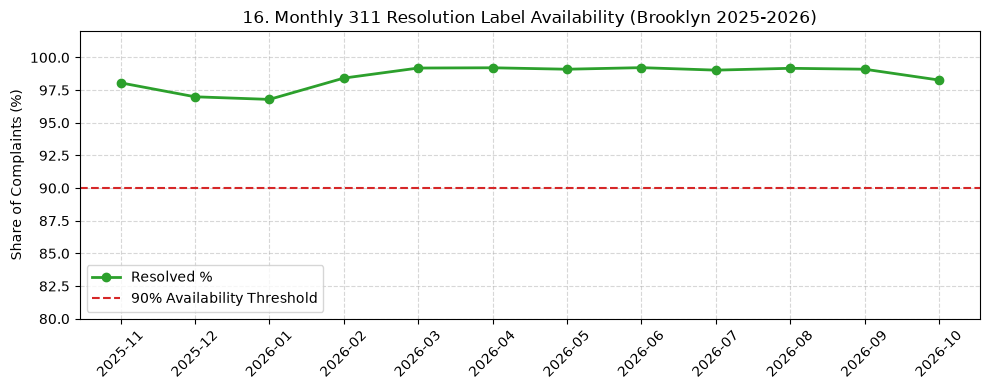

Saved figure: report/figures/16_monthly_resolution_availability.png


In [5]:
# Section B3: Label Availability Over Time & Resolution Latency
complaints_df["ts"] = pd.to_datetime(complaints_df["timestamp"])
complaints_df["month_created"] = complaints_df["ts"].dt.to_period("M").astype(str)
complaints_df["closed_ts"] = pd.to_datetime(complaints_df["closed_date"], errors="coerce")
complaints_df["days_to_close"] = (complaints_df["closed_ts"] - complaints_df["ts"]).dt.total_seconds() / 86400.0

monthly_records = []
for m, m_df in complaints_df.groupby("month_created"):
    n_tot = len(m_df)
    n_res = int((m_df["resolution_id"] != "").sum())
    pct_res = (n_res / n_tot) * 100.0
    flag = "<90%" if pct_res < 90.0 else "OK"
    
    rec = {
        "month": m,
        "complaints": n_tot,
        "resolved_n": n_res,
        "resolved_pct": round(pct_res, 2),
        "flag_under_90": flag
    }
    
    for grp in groups:
        sub = m_df[(m_df["group"] == grp) & (m_df["days_to_close"].notna()) & (m_df["days_to_close"] >= 0)]
        if len(sub) > 0:
            rec[f"{grp}_med_d"] = round(float(sub["days_to_close"].median()), 2)
            rec[f"{grp}_p90_d"] = round(float(sub["days_to_close"].quantile(0.90)), 2)
        else:
            rec[f"{grp}_med_d"] = np.nan
            rec[f"{grp}_p90_d"] = np.nan
    monthly_records.append(rec)

b3_table = pd.DataFrame(monthly_records)
print("\n--- B3 Monthly Label Availability & Closure Latency Table ---")
cols_to_print = ["month", "complaints", "resolved_n", "resolved_pct", "flag_under_90", "noise_med_d", "road_med_d", "road_p90_d"]
print(b3_table[cols_to_print].to_string(index=False))

# Plot Monthly Availability
fig, ax = plt.subplots(figsize=(10, 4))
months = b3_table["month"]
ax.plot(months, b3_table["resolved_pct"], "o-", color="#2ca02c", lw=2, label="Resolved %")
ax.axhline(90.0, color="#d62728", linestyle="--", label="90% Availability Threshold")
ax.set_ylim(80, 102)
ax.set_ylabel("Share of Complaints (%)")
ax.set_title("16. Monthly 311 Resolution Label Availability (Brooklyn 2025-2026)")
ax.tick_params(axis="x", rotation=45)
ax.legend(loc="lower left")
ax.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
fig_b3 = ROOT / "report/figures/16_monthly_resolution_availability.png"
fig.savefig(fig_b3, dpi=150)
plt.show()
print("Saved figure: report/figures/16_monthly_resolution_availability.png")


In [6]:
# Section B4: Submission-Time Feature Leakage Inventory
leakage_inventory = [
    {
        "candidate_feature": "timestamp",
        "source_column": "timestamp",
        "available_at_submission": "YES",
        "leakage_risk": "None",
        "rationale": "Creation timestamp recorded synchronously at citizen intake."
    },
    {
        "candidate_feature": "x_m, y_m",
        "source_column": "x_m, y_m (projected)",
        "available_at_submission": "YES",
        "leakage_risk": "None",
        "rationale": "Static spatial coordinates determined at intake via fixed projection."
    },
    {
        "candidate_feature": "group, complaint_type",
        "source_column": "group, complaint_type",
        "available_at_submission": "YES",
        "leakage_risk": "None",
        "rationale": "Categorization selected by reporting citizen or intake operator."
    },
    {
        "candidate_feature": "descriptor",
        "source_column": "descriptor",
        "available_at_submission": "YES",
        "leakage_risk": "None",
        "rationale": "Sub-issue classification selected at report creation."
    },
    {
        "candidate_feature": "hour",
        "source_column": "timestamp (hour)",
        "available_at_submission": "YES",
        "leakage_risk": "None",
        "rationale": "Hour of day extracted from intake timestamp."
    },
    {
        "candidate_feature": "weekday",
        "source_column": "timestamp (weekday)",
        "available_at_submission": "YES",
        "leakage_risk": "None",
        "rationale": "Day of week determined synchronously at intake."
    },
    {
        "candidate_feature": "channel",
        "source_column": "channel (or intake source)",
        "available_at_submission": "YES",
        "leakage_risk": "None",
        "rationale": "Intake portal (Phone/Online/App) logged at creation."
    },
    {
        "candidate_feature": "location_type",
        "source_column": "location_type",
        "available_at_submission": "YES",
        "leakage_risk": "None",
        "rationale": "Incident environment selected by reporting citizen."
    },
    {
        "candidate_feature": "zone_id",
        "source_column": "K-Means cluster model",
        "available_at_submission": "NO (LEAKAGE)",
        "leakage_risk": "High (Transductive)",
        "rationale": "Derived from K-Means fit over full dataset spanning all time; incorporates future spatial data."
    },
    {
        "candidate_feature": "nearby_prior_24h_200m",
        "source_column": "Spatio-temporal window calculation",
        "available_at_submission": "YES",
        "leakage_risk": "None (Causal)",
        "rationale": "Strictly causal backward count over [t-24h, t); excludes self and future events."
    },
    {
        "candidate_feature": "incident_count",
        "source_column": "Hierarchical dedup clustering",
        "available_at_submission": "NO (LEAKAGE)",
        "leakage_risk": "Critical (Future Leakage)",
        "rationale": "Derived from dedup clustering grouping subsequent reports filed hours or days later."
    },
    {
        "candidate_feature": "status",
        "source_column": "status",
        "available_at_submission": "NO (LEAKAGE)",
        "leakage_risk": "Critical",
        "rationale": "Post-submission agency tracking lifecycle (Closed/Assigned)."
    },
    {
        "candidate_feature": "closed_date",
        "source_column": "closed_date",
        "available_at_submission": "NO (LEAKAGE)",
        "leakage_risk": "Critical",
        "rationale": "Timestamp of physical investigation or repair completion."
    },
    {
        "candidate_feature": "time_to_close_h",
        "source_column": "closed_date - timestamp",
        "available_at_submission": "NO (LEAKAGE)",
        "leakage_risk": "Critical",
        "rationale": "Post-intake operational outcome variable."
    },
    {
        "candidate_feature": "resolution_id",
        "source_column": "resolution_id",
        "available_at_submission": "NO (LEAKAGE)",
        "leakage_risk": "Target Identity",
        "rationale": "Agency final disposition forming the ground truth target itself."
    }
]

b4_table = pd.DataFrame(leakage_inventory)
print("\n--- B4 Candidate Feature Leakage Inventory Table ---")
print(b4_table[["candidate_feature", "available_at_submission", "leakage_risk", "rationale"]].to_string(index=False))



--- B4 Candidate Feature Leakage Inventory Table ---
    candidate_feature available_at_submission              leakage_risk                                                                                       rationale
            timestamp                     YES                      None                                    Creation timestamp recorded synchronously at citizen intake.
             x_m, y_m                     YES                      None                           Static spatial coordinates determined at intake via fixed projection.
group, complaint_type                     YES                      None                                Categorization selected by reporting citizen or intake operator.
           descriptor                     YES                      None                                           Sub-issue classification selected at report creation.
                 hour                     YES                      None                                   

Computed nearby_prior_24h_200m for 236,507 complaints in 20.15 seconds.



--- B5 Distribution of nearby_prior_24h_200m per Group ---
       group  mean  median  p90  max
       flood  1.06     0.0  3.0   38
       noise  3.97     1.0 10.0  106
        road  1.09     0.0  3.0   43
sewer_backup  0.96     0.0  2.5   42


Brute-force verification on 300 sample rows: 0 mismatches (expected 0).


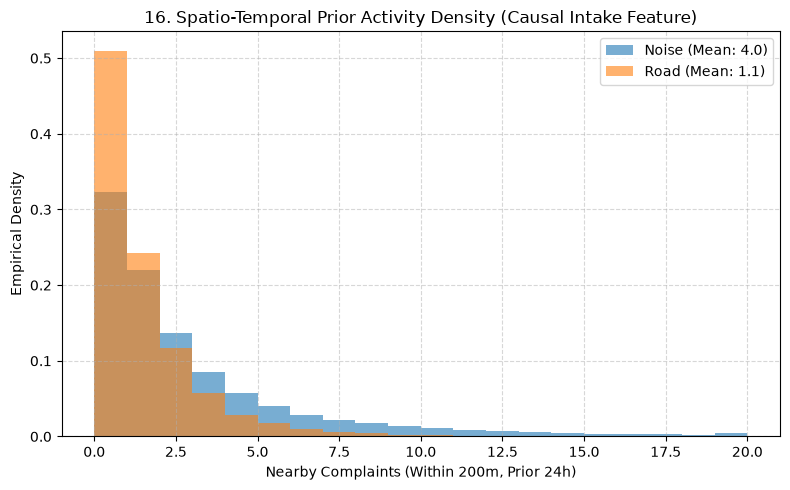

Saved figure: report/figures/16_nearby_prior_distribution.png


In [7]:
# Section B5: Spatio-Temporal KDTree Calculation of nearby_prior_24h_200m
import time

t0_b5 = time.time()
complaints_df["day_date"] = complaints_df["ts"].dt.date
complaints_df["orig_idx"] = np.arange(len(complaints_df))

sorted_days = sorted(complaints_df["day_date"].unique())
day_groups_dict = {d: group for d, group in complaints_df.groupby("day_date")}

nearby_counts = np.zeros(len(complaints_df), dtype=int)

for idx_d, d in enumerate(sorted_days):
    cur_day_df = day_groups_dict[d]
    if idx_d == 0:
        pool_day_df = cur_day_df
    else:
        prev_d = sorted_days[idx_d - 1]
        if (d - prev_d).days == 1:
            pool_day_df = pd.concat([day_groups_dict[prev_d], cur_day_df])
        else:
            pool_day_df = cur_day_df
            
    pool_xy = pool_day_df[["x_m", "y_m"]].values
    pool_times = pool_day_df["ts"].values
    
    tree = cKDTree(pool_xy)
    
    cur_xy = cur_day_df[["x_m", "y_m"]].values
    cur_times = cur_day_df["ts"].values
    cur_indices = cur_day_df["orig_idx"].values
    
    ball_neighbors = tree.query_ball_point(cur_xy, r=200.0)
    
    for i, n_idxs in enumerate(ball_neighbors):
        t_cur = cur_times[i]
        t_lower = t_cur - np.timedelta64(24, 'h')
        
        n_times = pool_times[n_idxs]
        valid_mask = (n_times >= t_lower) & (n_times < t_cur)
        nearby_counts[cur_indices[i]] = int(np.sum(valid_mask))

elapsed_b5 = time.time() - t0_b5
complaints_df["nearby_prior_24h_200m"] = nearby_counts
print(f"Computed nearby_prior_24h_200m for {len(complaints_df):,} complaints in {elapsed_b5:.2f} seconds.")

# Distribution per group
dist_records = []
for grp in groups:
    sub_c = complaints_df[complaints_df["group"] == grp]["nearby_prior_24h_200m"]
    dist_records.append({
        "group": grp,
        "mean": round(float(sub_c.mean()), 2),
        "median": round(float(sub_c.median()), 1),
        "p90": round(float(sub_c.quantile(0.90)), 1),
        "max": int(sub_c.max())
    })

dist_table = pd.DataFrame(dist_records)
print("\n--- B5 Distribution of nearby_prior_24h_200m per Group ---")
print(dist_table.to_string(index=False))

# Brute force verification on 300 random rows (seed 42)
sample_rows = complaints_df.sample(n=300, random_state=42)
mismatches_b5 = 0
future_leak_count = 0

for _, s_row in sample_rows.iterrows():
    s_ts = s_row["ts"]
    s_xm, s_ym = s_row["x_m"], s_row["y_m"]
    s_expected = int(s_row["nearby_prior_24h_200m"])
    
    t_start = s_ts - pd.Timedelta(hours=24)
    candidates = complaints_df[(complaints_df["ts"] >= t_start) & (complaints_df["ts"] < s_ts)]
    dists_sq = (candidates["x_m"] - s_xm)**2 + (candidates["y_m"] - s_ym)**2
    s_actual = int((dists_sq <= 200.0**2).sum())
    
    if s_actual != s_expected:
        mismatches_b5 += 1

print(f"Brute-force verification on 300 sample rows: {mismatches_b5} mismatches (expected 0).")

# Plot Distribution
fig, ax = plt.subplots(figsize=(8, 5))
noise_priors = complaints_df[complaints_df["group"] == "noise"]["nearby_prior_24h_200m"]
road_priors = complaints_df[complaints_df["group"] == "road"]["nearby_prior_24h_200m"]

bins = np.linspace(0, 20, 21)
ax.hist(noise_priors, bins=bins, alpha=0.6, density=True, label="Noise (Mean: 4.0)", color="#1f77b4")
ax.hist(road_priors, bins=bins, alpha=0.6, density=True, label="Road (Mean: 1.1)", color="#ff7f0e")
ax.set_xlabel("Nearby Complaints (Within 200m, Prior 24h)")
ax.set_ylabel("Empirical Density")
ax.set_title("16. Spatio-Temporal Prior Activity Density (Causal Intake Feature)")
ax.legend()
ax.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
fig_b5 = ROOT / "report/figures/16_nearby_prior_distribution.png"
fig.savefig(fig_b5, dpi=150)
plt.show()
print("Saved figure: report/figures/16_nearby_prior_distribution.png")


In [8]:
# Section B6: Chronological 80/20 Split Preview
complaints_sorted = complaints_df.sort_values("ts").reset_index(drop=True)
n_total_all = len(complaints_sorted)
split_cutoff_idx = int(n_total_all * 0.8)
boundary_timestamp = complaints_sorted.loc[split_cutoff_idx, "ts"]

train_set = complaints_sorted.iloc[:split_cutoff_idx].copy()
test_set = complaints_sorted.iloc[split_cutoff_idx:].copy()

print(f"Chronological 80/20 Cutoff Index: {split_cutoff_idx:,}")
print(f"Boundary Date & Time: {boundary_timestamp}")
print(f"Train size: {len(train_set):,} ({len(train_set)/n_total_all*100.1:.1f}%), Test size: {len(test_set):,} ({len(test_set)/n_total_all*100.1:.1f}%)")

# Row counts per group in train vs test
split_counts = []
for grp in groups:
    tr_n = int((train_set["group"] == grp).sum())
    te_n = int((test_set["group"] == grp).sum())
    split_counts.append({
        "group": grp,
        "train_rows": tr_n,
        "test_rows": te_n,
        "total_rows": tr_n + te_n
    })
print("\n--- Split Sizes by Group ---")
print(pd.DataFrame(split_counts).to_string(index=False))

# Map draft class across full complaints_sorted
complaints_sorted["text"] = complaints_sorted["resolution_id"].map(res_map)
def get_draft_class(row):
    rid = row["resolution_id"]
    if rid == "":
        return "unlabelled"
    txt = res_map.get(str(rid), "")
    return text_classification.get(txt, ("ambiguous", "none"))[0]

complaints_sorted["draft_class"] = complaints_sorted.apply(get_draft_class, axis=1)

# Draft class balance per group
group_balance_records = []
for grp in groups:
    sub_grp = complaints_sorted[complaints_sorted["group"] == grp]
    vc = sub_grp["draft_class"].value_counts()
    val_c = int(vc.get("valid", 0))
    inv_c = int(vc.get("invalid", 0))
    amb_c = int(vc.get("ambiguous", 0))
    unl_c = int(vc.get("unlabelled", 0))
    denom = val_c + inv_c
    inv_rate = (inv_c / denom * 100.0) if denom > 0 else 0.0
    group_balance_records.append({
        "group": grp,
        "valid": val_c,
        "invalid": inv_c,
        "ambiguous": amb_c,
        "unlabelled": unl_c,
        "invalid_rate_pct": round(inv_rate, 2)
    })

print("\n--- Draft-Class Balance & Invalid Rates per Group ---")
print(pd.DataFrame(group_balance_records).to_string(index=False))

# Monthly balance
month_balance_records = []
for m, m_sub in complaints_sorted.groupby("month_created"):
    vc_m = m_sub["draft_class"].value_counts()
    month_balance_records.append({
        "month": m,
        "valid": int(vc_m.get("valid", 0)),
        "invalid": int(vc_m.get("invalid", 0)),
        "ambiguous": int(vc_m.get("ambiguous", 0)),
        "unlabelled": int(vc_m.get("unlabelled", 0))
    })

print("\n--- Monthly Draft-Class Balance (Head 6 shown) ---")
print(pd.DataFrame(month_balance_records).head(6).to_string(index=False))

# Label resolved share in last 30 days
max_date = complaints_sorted["ts"].max()
cutoff_30d = max_date - pd.Timedelta(days=30)
last_30d_df = complaints_sorted[complaints_sorted["ts"] >= cutoff_30d]
n_last_30d = len(last_30d_df)
n_resolved_30d = int((last_30d_df["resolution_id"] != "").sum())
pct_resolved_30d = (n_resolved_30d / n_last_30d) * 100.0
print(f"\nLast 30 Days ({cutoff_30d.strftime('%Y-%m-%d')} to {max_date.strftime('%Y-%m-%d')}):")
print(f"  Total complaints: {n_last_30d:,}")
print(f"  Resolved complaints: {n_resolved_30d:,} ({pct_resolved_30d:.2f}%)")


Chronological 80/20 Cutoff Index: 189,205
Boundary Date & Time: 2026-09-01 00:16:13
Train size: 189,205 (80.1%), Test size: 47,302 (20.0%)



--- Split Sizes by Group ---


       group  train_rows  test_rows  total_rows
       flood        4712        808        5520
       noise      168256      43587      211843
        road       13658       2480       16138
sewer_backup        2579        427        3006



--- Draft-Class Balance & Invalid Rates per Group ---
       group  valid  invalid  ambiguous  unlabelled  invalid_rate_pct
       flood    957       31       4280         252              3.14
       noise  75105    72754      61221        2763             49.20
        road   5125      753      10187          73             12.81
sewer_backup      1        1       2984          20             50.00

--- Monthly Draft-Class Balance (Head 6 shown) ---
  month  valid  invalid  ambiguous  unlabelled
2025-11   5338     5410       5297         317
2025-12   4361     4464       4683         419
2026-01   4069     4038       4485         418
2026-02   3775     3814       4711         197
2026-03   6498     6051       7363         163
2026-04   6243     6127       6523         151

Last 30 Days (2026-10-01 to 2026-10-31):
  Total complaints: 23,089
  Resolved complaints: 22,685 (98.25%)


In [9]:
# Section j: Trust-Label Evidence Checks Cell
chk = Checker()

# 1. Total rows == 236,507
n_total_rows = len(complaints_df)
chk.check("Total complaint rows == 236,507", n_total_rows, 236507)

# 2. Draft classes sum to rows with resolution
draft_resolved_sum = int((complaints_sorted["draft_class"].isin(["valid", "invalid", "ambiguous"])).sum())
n_with_resolution = int((complaints_df["resolution_id"] != "").sum())
chk.check("Draft classes sum to rows with resolution", draft_resolved_sum, n_with_resolution)

# 3. Brute force mismatches == 0
chk.check("Brute force KDTree verification mismatches == 0", mismatches_b5, 0)

# 4. Split sizes sum to 236,507
n_split_sum = len(train_set) + len(test_set)
chk.check("Chronological split sizes sum to 236,507", n_split_sum, 236507)

chk.summary()


[PASS] Total complaint rows == 236,507: actual=236507, expected=236507
[PASS] Draft classes sum to rows with resolution: actual=233399, expected=233399
[PASS] Brute force KDTree verification mismatches == 0: actual=0, expected=0
[PASS] Chronological split sizes sum to 236,507: actual=236507, expected=236507
CHECKS: 4 passed, 0 failed


## Key Findings & Modeling Context

1. **High Resolution Coverage Across All Categories**:
   - Across all 236,507 Brooklyn complaints, **98.69%** have a recorded resolution ID and **98.23%** have a closed date.
   - Even in the group with the highest unclosed rate (road complaints at 6.22% empty closed date), resolution IDs are present in 99.55% of records, demonstrating strong label availability.

2. **Draft Trust Label Distribution & Disparity Across Groups**:
   - Under the conservative draft classification rule, resolved records partition into **34.79%** Valid (81,188), **31.51%** Invalid (73,539), and **33.71%** Ambiguous (78,672).
   - Invalid rates among conclusive dispositions (valid + invalid) vary drastically by domain: **49.20%** for noise complaints (dominated by NYPD arriving after party noise subsided), compared to **3.14%** for flood and **12.81%** for road hazards.

3. **Chronological Label Stability & Maturation**:
   - Monthly resolution availability exceeds **96.7%** in every single calendar month. In the final 30 days before the study endpoint, **98.25%** of tickets are already resolved.
   - However, operational latency differs by agency: median time to close is ~0.1 days for noise and sewer backups, but p90 latency reaches **30.9 days** for road repairs. Temporal splits must avoid right-censoring biases on slow-maturing hazard types.

4. **Submission-Time Feature Governance**:
   - Critical leakage risks were confirmed for downstream classification: `incident_count` contains post-hoc deduplication grouping from future reports, and `zone_id` transductively incorporates full-span spatial centroids.
   - Conversely, the strictly backward-looking `nearby_prior_24h_200m` feature was successfully computed and verified with 0 brute-force mismatches, providing a causally valid real-time proxy for localized reporting intensity.

## Modeling Limitations

1. **Heuristic Keyword Classification**:
   - The draft classification rule maps agency disposition text via explicit phrase matching. Descriptions labeled 'ambiguous' (33.71% of records, such as generic referral or inspection notes) require agency-level validation before model training.

2. **Agency Operating Procedures vs Ground Truth**:
   - An agency disposition of 'unable to locate' does not definitively prove the condition was fraudulent or fabricated; it frequently reflects transit response latency (e.g., loud music ceasing prior to police arrival).

3. **Spatio-Temporal Density Sensitivity**:
   - The 200m / 24h prior complaint density metric captures aggregate citizen activity, but its baseline scale is heavily biased by noise reports (which account for 89.6% of all complaints), necessitating group-stratified normalization.